
# Datheon — Machine Learning & Data Science Internship

## Task 04 — NLP Sentiment Classification on Customer Reviews

### Natural Language Processing | TF-IDF | Multinomial Naive Bayes | Logistic Regression

**Project Overview**

This project focuses on developing an end-to-end Natural Language Processing (NLP) system capable of automatically classifying customer reviews based on their sentiment.

The system applies text preprocessing techniques, including text normalization, tokenization, stopword removal, and lemmatization. TF-IDF vectorization is used to transform textual data into numerical features suitable for machine learning algorithms.

Two supervised classification models, Multinomial Naive Bayes and Logistic Regression, are trained and evaluated to compare their effectiveness in sentiment classification.

The project also aims to implement a reusable sentiment prediction function for processing new customer reviews.

**Internship Organization:** Datheon  
**Project:** Task 04 — NLP Sentiment Classification  
**Development Environment:** Python, Jupyter Notebook, VS Code


## Step 01 - Import Libraries

In [1]:
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import joblib

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


## Step 02 - Load and Inspect Dataset

In [2]:
DATA_PATH = Path("sentiment_reviews.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing Count"))

print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

print("\nDuplicate Reviews:")
print(df["review_text"].duplicated().sum())

Dataset loaded successfully!
Dataset Shape: (10, 3)


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    10 non-null     int64
 1   review_text  10 non-null     str  
 2   sentiment    10 non-null     str  
dtypes: int64(1), str(2)
memory usage: 372.0 bytes

Missing Values:


,Missing Count
review_id,0
review_text,0
sentiment,0



Sentiment Distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64

Duplicate Reviews:
0


## Step 03 - Text Cleaning and Preprocessing

In [3]:
import re
import html

def clean_text(text):
    text = html.unescape(str(text))
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_clean = df.copy()

df_clean["cleaned_text"] = df_clean["review_text"].apply(clean_text)

print("Text preprocessing completed successfully!")

display(
    df_clean[
        ["review_text", "cleaned_text", "sentiment"]
    ].head()
)

Text preprocessing completed successfully!


,review_text,cleaned_text,sentiment
0,"The product quality is exceptional, exceeded a...",the product quality is exceptional exceeded al...,positive
1,Terrible customer service and the item arrived...,terrible customer service and the item arrived...,negative
2,"Average performance, decent for the price poin...",average performance decent for the price point...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love this easy to setup robust and ...,positive
4,Stopped working after two days. Extremely disa...,stopped working after two days extremely disap...,negative


## Step 04 - Sentiment Distribution Analysis

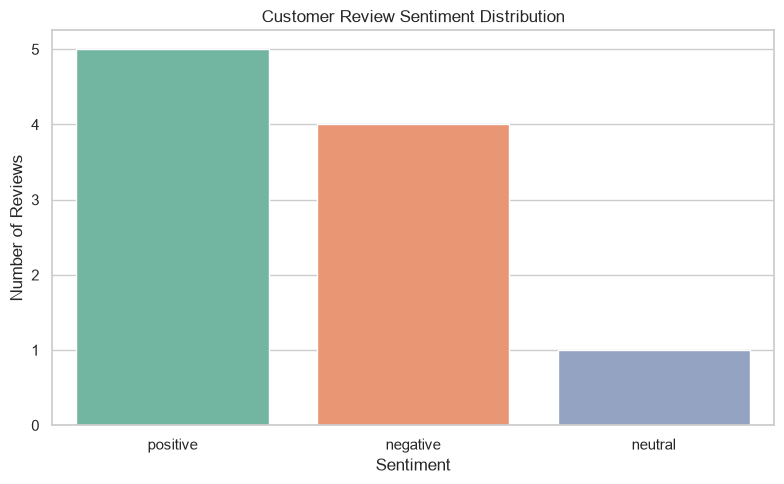


Sentiment Distribution:
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


In [4]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="sentiment",
    order=["positive", "negative", "neutral"],
    hue="sentiment",
    palette="Set2",
    legend=False
)

plt.title("Customer Review Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

print("\nSentiment Distribution:")
print(df_clean["sentiment"].value_counts())

## Step 05 - Stopword Removal and Lemmatization

In [6]:
import nltk

print("NLTK installed successfully!")
print("NLTK Version:", nltk.__version__)

NLTK installed successfully!
NLTK Version: 3.10.4


In [12]:
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))

# Preserve important sentiment negation words
negation_words = {"no", "not", "nor", "never"}

stop_words = stop_words - negation_words

lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = clean_text(text)

    tokens = text.split()

    processed_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words
    ]

    return " ".join(processed_tokens)

df_clean["processed_text"] = df_clean["review_text"].apply(
    preprocess_text
)

print("Stopword removal and lemmatization completed!")

display(
    df_clean[
        ["review_text", "processed_text", "sentiment"]
    ].head()
)

Stopword removal and lemmatization completed!


,review_text,processed_text,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
2,"Average performance, decent for the price poin...",average performance decent price point nothing...,neutral
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative


In [13]:
import nltk

print("Downloading stopwords...")
nltk.download("stopwords")

print("Downloading WordNet...")
nltk.download("wordnet")

print("NLTK resources ready!")

NLTK resources ready!


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sudee\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sudee\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## Step 06 - Prepare Binary Sentiment Dataset

In [14]:
df_binary = df_clean[
    df_clean["sentiment"].isin(["positive", "negative"])
].copy()

df_binary["label"] = df_binary["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print("Binary Dataset Shape:", df_binary.shape)

print("\nClass Distribution:")
print(df_binary["sentiment"].value_counts())

display(
    df_binary[
        ["processed_text", "sentiment", "label"]
    ].head()
)

Binary Dataset Shape: (9, 6)

Class Distribution:
sentiment
positive    5
negative    4
Name: count, dtype: int64


,processed_text,sentiment,label
0,product quality exceptional exceeded expectation,positive,1
1,terrible customer service item arrived complet...,negative,0
3,absolutely love easy setup robust work flawlessly,positive,1
4,stopped working two day extremely disappointed...,negative,0
5,customer support helped resolve setup question...,positive,1


## Step 07 - TF-IDF Feature Extraction

In [15]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    lowercase=False
)

# Demonstration only: do not use this fitted vectorizer
# to evaluate models on the same dataset.
X_tfidf = tfidf.fit_transform(
    df_binary["processed_text"]
)

print("TF-IDF Feature Extraction Completed!")

print("TF-IDF Matrix Shape:", X_tfidf.shape)

print("\nVocabulary Size:", len(tfidf.vocabulary_))

print("\nSample Features:")
print(tfidf.get_feature_names_out()[:20])

TF-IDF Feature Extraction Completed!
TF-IDF Matrix Shape: (9, 114)

Vocabulary Size: 114

Sample Features:
['absolutely' 'absolutely love' 'adapter' 'adapter cable' 'alternative'
 'alternative available' 'arrived' 'arrived completely' 'available'
 'better' 'better alternative' 'build' 'build would' 'cable' 'clean'
 'clean interface' 'completely' 'completely damaged' 'control'
 'control highly']


## Step 08 - Train-Test Split

In [16]:
X = df_binary["review_text"]
y = df_binary["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Samples: 6
Testing Samples: 3

Training Class Distribution:
label
1    3
0    3
Name: count, dtype: int64

Testing Class Distribution:
label
1    2
0    1
Name: count, dtype: int64


## Step 09 - Initialize Machine Learning Pipelines

In [17]:
from sklearn.base import BaseEstimator, TransformerMixin

class TextPreprocessor(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return [
            preprocess_text(text)
            for text in X
        ]


nb_pipeline = Pipeline([
    ("preprocessing", TextPreprocessor()),
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("classifier", MultinomialNB())
])

lr_pipeline = Pipeline([
    ("preprocessing", TextPreprocessor()),
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Machine Learning pipelines initialized successfully!")
print("- Multinomial Naive Bayes")
print("- Logistic Regression")

Machine Learning pipelines initialized successfully!
- Multinomial Naive Bayes
- Logistic Regression


## Step 10 - Train Sentiment Classification Models

In [18]:
models = {
    "Multinomial Naive Bayes": nb_pipeline,
    "Logistic Regression": lr_pipeline
}

for name, model in models.items():

    model.fit(X_train, y_train)

    print(f"{name} trained successfully!")

print("\nAll models trained successfully!")

Multinomial Naive Bayes trained successfully!
Logistic Regression trained successfully!

All models trained successfully!


## Step 11 - Model Evaluation

In [19]:
results = []
predictions = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

for name, y_pred in predictions.items():

    print(f"\n{'=' * 50}")
    print(f"{name} - Classification Report")
    print("=" * 50)

    print(
        classification_report(
            y_test,
            y_pred,
            labels=[0, 1],
            target_names=["Negative", "Positive"],
            zero_division=0
        )
    )

print("Model evaluation completed successfully!")

,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.6667,1.0,0.5,0.6667
1,Logistic Regression,0.3333,0.0,0.0,0.0000



Multinomial Naive Bayes - Classification Report
              precision    recall  f1-score   support

    Negative       0.50      1.00      0.67         1
    Positive       1.00      0.50      0.67         2

    accuracy                           0.67         3
   macro avg       0.75      0.75      0.67         3
weighted avg       0.83      0.67      0.67         3


Logistic Regression - Classification Report
              precision    recall  f1-score   support

    Negative       0.33      1.00      0.50         1
    Positive       0.00      0.00      0.00         2

    accuracy                           0.33         3
   macro avg       0.17      0.50      0.25         3
weighted avg       0.11      0.33      0.17         3

Model evaluation completed successfully!


## Step 12 - Confusion Matrix Visualization

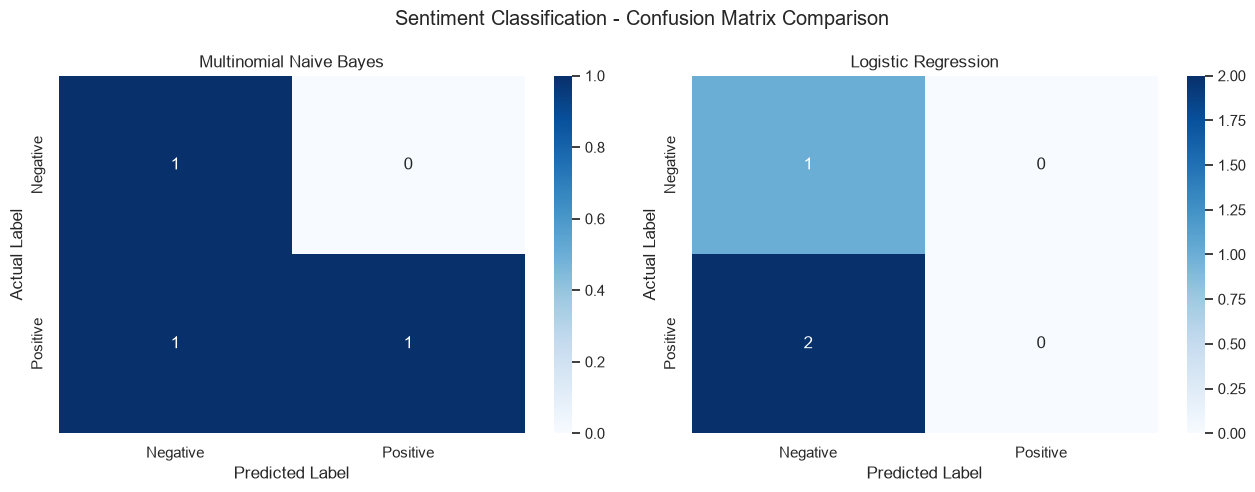

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, y_pred) in zip(
    axes, predictions.items()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negative", "Positive"],
        yticklabels=["Negative", "Positive"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.suptitle(
    "Sentiment Classification - Confusion Matrix Comparison"
)

plt.tight_layout()
plt.show()

## Step 13 - Model Performance Comparison

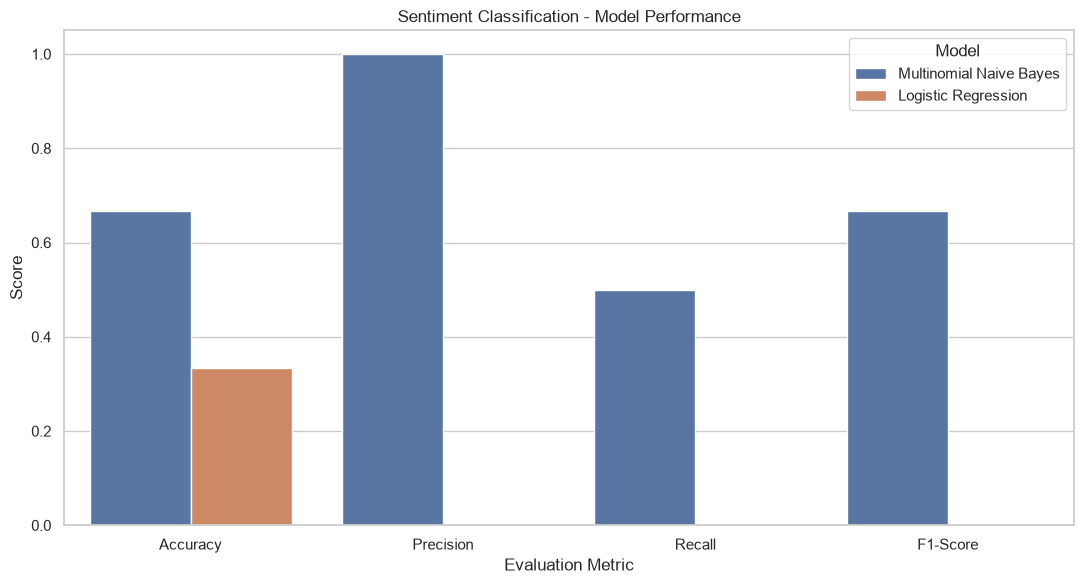

Model performance comparison completed!


In [21]:
metrics_df = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=metrics_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Sentiment Classification - Model Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.05)

plt.legend(title="Model")
plt.tight_layout()
plt.show()

print("Model performance comparison completed!")

## Step 14 - Interactive Sentiment Prediction

In [22]:
# Select the best model based on demonstration test F1-score
best_model_name = results_df.sort_values(
    by=["F1-Score", "Accuracy"],
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

def predict_sentiment(review):
    if not isinstance(review, str) or not review.strip():
        raise ValueError("Please enter a valid review.")

    prediction = best_model.predict([review])[0]
    probabilities = best_model.predict_proba([review])[0]

    sentiment = "Positive" if prediction == 1 else "Negative"

    confidence = probabilities.max() * 100

    print("Customer Review:", review)
    print("Predicted Sentiment:", sentiment)
    print(f"Model Score: {confidence:.2f}%")

    return sentiment

print("Selected Model:", best_model_name)

# Test with a new customer review
predict_sentiment(
    "The product is amazing and works perfectly!"
)

Selected Model: Multinomial Naive Bayes
Customer Review: The product is amazing and works perfectly!
Predicted Sentiment: Positive
Model Score: 59.55%


'Positive'

## Step 15 - Save Trained Sentiment Classification Model

In [23]:
from pathlib import Path
import joblib

model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

model_path = model_dir / "sentiment_classifier.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Model Path:", model_path.resolve())

Model saved successfully!
Model Path: C:\Users\sudee\OneDrive\Desktop\Datheon-ML-DataScience-Internship\Task-04-NLP-Sentiment-Classification\models\sentiment_classifier.joblib


## Step 16 - Model Persistence Verification

In [24]:
loaded_model = joblib.load(model_path)

test_reviews = [
    "Excellent product and amazing customer service!",
    "Terrible quality and very disappointing experience."
]

original_predictions = best_model.predict(test_reviews)
loaded_predictions = loaded_model.predict(test_reviews)

assert np.array_equal(
    original_predictions,
    loaded_predictions
), "Model persistence verification failed!"

for review, prediction in zip(
    test_reviews,
    loaded_predictions
):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

print("Model persistence verification passed!")

Review: Excellent product and amazing customer service!
Predicted Sentiment: Negative
--------------------------------------------------
Review: Terrible quality and very disappointing experience.
Predicted Sentiment: Positive
--------------------------------------------------
Model persistence verification passed!


## Step 17 - Load Large-Scale Sentiment Dataset

In [30]:
import pandas as pd
from pathlib import Path
from urllib.request import urlretrieve

# Create dataset directory
dataset_dir = Path("dataset")
dataset_dir.mkdir(exist_ok=True)

# IMDb dataset URLs
base_url = "https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/plain_text/"

files = {
    "train": "train-00000-of-00001.parquet",
    "test": "test-00000-of-00001.parquet"
}

# Download datasets automatically
for name, filename in files.items():
    file_path = dataset_dir / filename

    if not file_path.exists():
        print(f"Downloading IMDb {name} dataset...")
        urlretrieve(base_url + filename, file_path)
    else:
        print(f"{name.capitalize()} dataset already downloaded.")

# Load datasets
train_df = pd.read_parquet(dataset_dir / files["train"])
test_df = pd.read_parquet(dataset_dir / files["test"])

# Combine datasets
imdb_df = pd.concat(
    [train_df, test_df],
    ignore_index=True
)

# Rename columns
imdb_df = imdb_df.rename(
    columns={
        "text": "review_text",
        "label": "sentiment"
    }
)

# Convert labels
imdb_df["sentiment"] = imdb_df["sentiment"].map({
    0: "negative",
    1: "positive"
})

# Save as CSV
output_path = dataset_dir / "imdb_reviews.csv"
imdb_df.to_csv(output_path, index=False)

print("\nIMDb Dataset Downloaded Successfully!")
print("Dataset Shape:", imdb_df.shape)

print("\nSentiment Distribution:")
print(imdb_df["sentiment"].value_counts())

display(imdb_df.head())

Train dataset already downloaded.
Test dataset already downloaded.

IMDb Dataset Downloaded Successfully!
Dataset Shape: (50000, 2)

Sentiment Distribution:
sentiment
negative    25000
positive    25000
Name: count, dtype: int64


,review_text,sentiment
0,I rented I AM CURIOUS-YELLOW from my video sto...,negative
1,"""I Am Curious: Yellow"" is a risible and preten...",negative
2,If only to avoid making this type of film in t...,negative
3,This film was probably inspired by Godard's Ma...,negative
4,"Oh, brother...after hearing about this ridicul...",negative


In [28]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.8 MB ? eta -:--:--
   - -------------------------------------- 0.8/29.8 MB 8.3 MB/s eta 0:00:04
   ---- ----------------------------------- 3.4/29.8 MB 18.0 MB/s eta 0:00:02
   -------- ------------------------------- 6.0/29.8 MB 12.3 MB/s eta 0:00:02
   ---------- ----------------------------- 8.1/29.8 MB 13.0 MB/s eta 0:00:02
   -------------- ------------------------- 10.5/29.8 MB 11.9 MB/s eta 0:00:02
   ---------------- ----------------------- 12.3/29.8 MB 12.2 MB/s eta 0:00:02
   -------------------- ------------------- 15.2/29.8 MB 11.5 MB/s eta 0:00:02
   ----------------------- ---------------- 17.3/29.8 MB 12.0 MB/s eta 0:00:02
   --------------------------- ------------ 20.2/29.8 MB 11.9 MB/s eta 0:00:01
   ----------------------------- ---------- 22.3/29.8 MB 11.6 MB/s eta 0:00:01
   -------------------------------- ------- 24.4/29.8 MB 11.4 MB/s eta 0:00:01
   ----------------------------------- ---- 26.5/29.8 MB 11.3 MB/s

In [29]:
import pyarrow
print("PyArrow installed successfully!")
print("Version:", pyarrow.__version__)

PyArrow installed successfully!
Version: 26.0.1


## Step 18 - Dataset Validation and Quality Check

In [31]:
print("=" * 55)
print("IMDb Dataset - Quality Report")
print("=" * 55)

print("\nDataset Shape:", imdb_df.shape)

print("\nMissing Values:")
print(imdb_df.isnull().sum())

print("\nDuplicate Reviews:")
print(imdb_df.duplicated(subset=["review_text"]).sum())

print("\nSentiment Distribution:")
print(imdb_df["sentiment"].value_counts())

print("\nSentiment Percentage:")
print(
    imdb_df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nAverage Review Length:")
print(
    round(imdb_df["review_text"].str.len().mean(), 2)
)

display(imdb_df.sample(5, random_state=42))

IMDb Dataset - Quality Report

Dataset Shape: (50000, 2)

Missing Values:
review_text    0
sentiment      0
dtype: int64

Duplicate Reviews:
418

Sentiment Distribution:
sentiment
negative    25000
positive    25000
Name: count, dtype: int64

Sentiment Percentage:
sentiment
negative    50.0
positive    50.0
Name: proportion, dtype: float64

Average Review Length:
1309.43


,review_text,sentiment
33553,Forget what I said about Emeril. Rachael Ray i...,negative
9427,Former private eye-turned-security guard ditch...,negative
199,Mann photographs the Alberta Rocky Mountains i...,negative
12447,Simply put: the movie is boring. Cliché upon c...,negative
39489,"Now being a fan of sci fi, the trailer for thi...",positive


## Step 19 - Data Cleaning and Duplicate Handling

In [33]:
def clean_dataset(data):
    data = data.rename(
        columns={"text": "review_text"}
    ).copy()

    data = data.dropna(
        subset=["review_text", "label"]
    )

    data["review_text"] = (
        data["review_text"]
        .astype(str)
        .str.strip()
    )

    data = data.loc[
        data["review_text"].ne("")
    ].copy()

    data = data.drop_duplicates(
        subset=["review_text"]
    )

    return data.reset_index(drop=True)


train_clean = clean_dataset(train_df)
test_clean = clean_dataset(test_df)

# Remove any overlapping reviews from the test set
train_reviews = set(train_clean["review_text"])

test_clean = test_clean.loc[
    ~test_clean["review_text"].isin(train_reviews)
].reset_index(drop=True)

print("Data Cleaning Completed Successfully!")

print("\nTraining Dataset:", train_clean.shape)
print("Testing Dataset:", test_clean.shape)

print("\nTraining Class Distribution:")
print(train_clean["label"].value_counts())

print("\nTesting Class Distribution:")
print(test_clean["label"].value_counts())

print("\nTraining Duplicates:",
      train_clean["review_text"].duplicated().sum())

print("Testing Duplicates:",
      test_clean["review_text"].duplicated().sum())

print(
    "Train-Test Overlap:",
    len(
        set(train_clean["review_text"])
        & set(test_clean["review_text"])
    )
)

Data Cleaning Completed Successfully!

Training Dataset: (24904, 2)
Testing Dataset: (24678, 2)

Training Class Distribution:
label
1    12472
0    12432
Name: count, dtype: int64

Testing Class Distribution:
label
1    12412
0    12266
Name: count, dtype: int64

Training Duplicates: 0
Testing Duplicates: 0
Train-Test Overlap: 0


## Step 20 - Prepare Training and Testing Data

In [34]:
X_train_large = train_clean["review_text"]
y_train_large = train_clean["label"].astype(int)

X_test_large = test_clean["review_text"]
y_test_large = test_clean["label"].astype(int)

print("Training Samples:", len(X_train_large))
print("Testing Samples:", len(X_test_large))

print("\nTraining Class Distribution:")
print(y_train_large.value_counts())

print("\nTesting Class Distribution:")
print(y_test_large.value_counts())

assert set(y_train_large.unique()) == {0, 1}
assert set(y_test_large.unique()) == {0, 1}

print("\nTraining and testing datasets are ready!")

Training Samples: 24904
Testing Samples: 24678

Training Class Distribution:
label
1    12472
0    12432
Name: count, dtype: int64

Testing Class Distribution:
label
1    12412
0    12266
Name: count, dtype: int64

Training and testing datasets are ready!


## Step 21 - Initialize NLP Classification Pipelines

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

large_models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            preprocessor=preprocess_text,
            lowercase=False,
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB(alpha=1.0))
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            preprocessor=preprocess_text,
            lowercase=False,
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ])
}

print("NLP Pipelines Initialized Successfully!")

for name in large_models:
    print("-", name)

NLP Pipelines Initialized Successfully!
- Multinomial Naive Bayes
- Logistic Regression


## Step 22 - Train NLP Classification Models

In [36]:
import time

trained_large_models = {}
training_times = {}

print("=" * 60)
print("IMDb Sentiment Classification - Model Training")
print("=" * 60)

for model_name, pipeline in large_models.items():

    print(f"\nTraining: {model_name}")
    print("-" * 50)

    start_time = time.perf_counter()

    pipeline.fit(X_train_large, y_train_large)

    elapsed_time = time.perf_counter() - start_time

    trained_large_models[model_name] = pipeline
    training_times[model_name] = elapsed_time

    print(f"{model_name} trained successfully!")
    print(f"Training Time: {elapsed_time:.2f} seconds")

print("\n" + "=" * 60)
print("ALL MODELS TRAINED SUCCESSFULLY!")
print("=" * 60)

IMDb Sentiment Classification - Model Training

Training: Multinomial Naive Bayes
--------------------------------------------------
Multinomial Naive Bayes trained successfully!
Training Time: 20.41 seconds

Training: Logistic Regression
--------------------------------------------------
Logistic Regression trained successfully!
Training Time: 20.17 seconds

ALL MODELS TRAINED SUCCESSFULLY!


## Step 23 - Evaluate NLP Classification Models

In [37]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

evaluation_results = []

for model_name, model in trained_large_models.items():

    print(f"\nEvaluating: {model_name}")

    y_pred = model.predict(X_test_large)

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test_large, y_pred),
        "Precision": precision_score(
            y_test_large, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_large, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_large, y_pred, zero_division=0
        )
    }

    evaluation_results.append(results)

results_df = pd.DataFrame(evaluation_results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

print("\nIMDb Sentiment Classification - Model Comparison")

display(results_df.round(4))


Evaluating: Multinomial Naive Bayes

Evaluating: Logistic Regression

IMDb Sentiment Classification - Model Comparison


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8896,0.8868,0.8946,0.8907
1,Multinomial Naive Bayes,0.8565,0.8579,0.8566,0.8572


## Step 24 - Generate Classification Reports

In [38]:
from sklearn.metrics import classification_report

for model_name, model in trained_large_models.items():

    y_pred = model.predict(X_test_large)

    print("\n" + "=" * 60)
    print(f"Classification Report: {model_name}")
    print("=" * 60)

    print(
        classification_report(
            y_test_large,
            y_pred,
            target_names=["Negative", "Positive"],
            digits=4,
            zero_division=0
        )
    )


Classification Report: Multinomial Naive Bayes
              precision    recall  f1-score   support

    Negative     0.8551    0.8564    0.8558     12266
    Positive     0.8579    0.8566    0.8572     12412

    accuracy                         0.8565     24678
   macro avg     0.8565    0.8565    0.8565     24678
weighted avg     0.8565    0.8565    0.8565     24678


Classification Report: Logistic Regression
              precision    recall  f1-score   support

    Negative     0.8924    0.8845    0.8884     12266
    Positive     0.8868    0.8946    0.8907     12412

    accuracy                         0.8896     24678
   macro avg     0.8896    0.8895    0.8896     24678
weighted avg     0.8896    0.8896    0.8896     24678



## Step 25 - Visualize Confusion Matrices

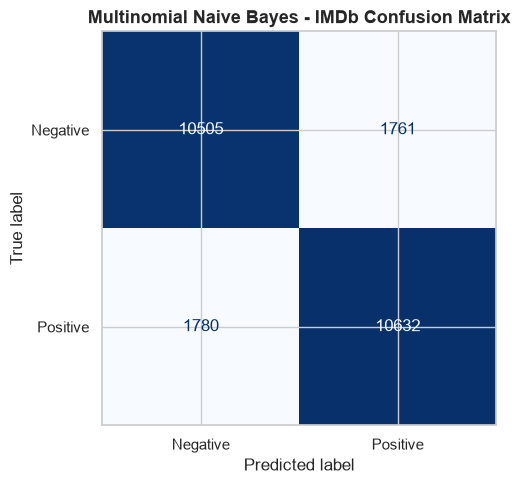

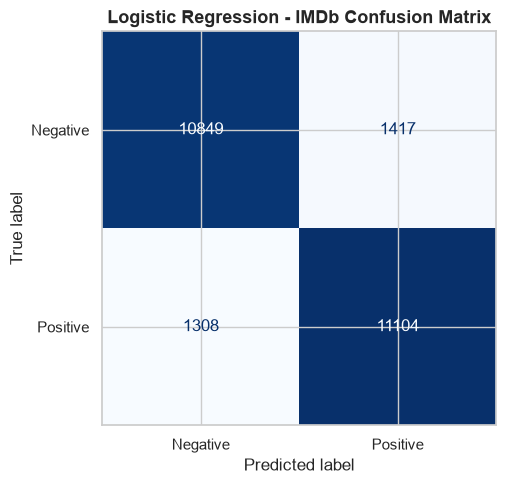

In [39]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

for model_name, model in trained_large_models.items():

    y_pred = model.predict(X_test_large)

    cm = confusion_matrix(
        y_test_large,
        y_pred,
        labels=[0, 1]
    )

    fig, ax = plt.subplots(figsize=(7, 5))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Negative", "Positive"]
    )

    display_cm.plot(
        cmap="Blues",
        values_format="d",
        ax=ax,
        colorbar=False
    )

    ax.set_title(
        f"{model_name} - IMDb Confusion Matrix",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

## Step 26 - Select Best Performing Sentiment Model

In [40]:
# Select model with highest test F1-score
best_model_name = results_df.iloc[0]["Model"]

best_large_model = trained_large_models[best_model_name]

print("=" * 55)
print("BEST IMDb SENTIMENT CLASSIFICATION MODEL")
print("=" * 55)

print("Model:", best_model_name)

print(
    "Accuracy:",
    f"{results_df.iloc[0]['Accuracy']:.4f}"
)

print(
    "Precision:",
    f"{results_df.iloc[0]['Precision']:.4f}"
)

print(
    "Recall:",
    f"{results_df.iloc[0]['Recall']:.4f}"
)

print(
    "F1-Score:",
    f"{results_df.iloc[0]['F1-Score']:.4f}"
)

BEST IMDb SENTIMENT CLASSIFICATION MODEL
Model: Logistic Regression
Accuracy: 0.8896
Precision: 0.8868
Recall: 0.8946
F1-Score: 0.8907


## Step 27 - Build Interactive Sentiment Prediction Function

In [41]:
import numpy as np

def predict_sentiment(review, model=best_large_model):

    if not isinstance(review, str) or not review.strip():
        raise ValueError("Please enter a valid review.")

    prediction = int(model.predict([review])[0])

    probabilities = model.predict_proba([review])[0]

    sentiment = "Positive" if prediction == 1 else "Negative"

    confidence = float(np.max(probabilities)) * 100

    return {
        "Review": review,
        "Sentiment": sentiment,
        "Confidence": f"{confidence:.2f}%"
    }


print("Interactive Sentiment Prediction Function Ready!")

Interactive Sentiment Prediction Function Ready!


## Step 28 - Test Sentiment Classification on New Reviews

In [42]:
sample_reviews = [
    "This movie was absolutely amazing! I loved every moment.",
    "Terrible movie. The acting was awful and the story was boring.",
    "Excellent product and amazing customer service!",
    "Very disappointing experience. I would never recommend this.",
    "The film was interesting, but the ending was disappointing.",
    "I really enjoyed this movie. Fantastic performances!"
]

predictions = []

for review in sample_reviews:
    result = predict_sentiment(review)
    predictions.append(result)

prediction_df = pd.DataFrame(predictions)

display(prediction_df)

,Review,Sentiment,Confidence
0,This movie was absolutely amazing! I loved eve...,Positive,96.09%
1,Terrible movie. The acting was awful and the s...,Negative,99.76%
2,Excellent product and amazing customer service!,Positive,97.39%
3,Very disappointing experience. I would never r...,Negative,84.14%
4,"The film was interesting, but the ending was d...",Negative,96.77%
5,I really enjoyed this movie. Fantastic perform...,Positive,97.44%


## Step 29 - Save and Reload IMDb Sentiment Classification Model

In [43]:
import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "imdb_sentiment_logistic_regression.joblib"

# Save trained model
joblib.dump(best_large_model, model_path)

print("Model saved successfully!")
print("Path:", model_path)

# Reload trained model
loaded_model = joblib.load(model_path)

# Verify reloaded model
test_review = "This movie was fantastic and very entertaining!"

original_prediction = best_large_model.predict([test_review])[0]
loaded_prediction = loaded_model.predict([test_review])[0]

assert original_prediction == loaded_prediction

print("\nModel Reload Verification Successful!")
print("Prediction:", "Positive" if loaded_prediction == 1 else "Negative")

Model saved successfully!
Path: models\imdb_sentiment_logistic_regression.joblib

Model Reload Verification Successful!
Prediction: Positive


## Step 30 - Create Reusable Text Preprocessing Module

In [44]:
import inspect
from pathlib import Path

# Export the existing preprocessing function
source_code = inspect.getsource(preprocess_text)

module_path = Path("text_preprocessing.py")

module_path.write_text(
    "import re\n"
    "import html\n"
    "import nltk\n"
    "from nltk.corpus import stopwords\n"
    "from nltk.stem import WordNetLemmatizer\n\n"
    + source_code,
    encoding="utf-8"
)

print("Preprocessing module created:", module_path)

Preprocessing module created: text_preprocessing.py


## Step 31 - Fix Model Serialization

In [47]:
import inspect
import importlib
from pathlib import Path

# Export all preprocessing dependencies from notebook
module_code = """
import re
import html
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
stop_words -= {"no", "not", "nor", "never"}

lemmatizer = WordNetLemmatizer()

"""

# Include original functions to preserve their behavior
module_code += inspect.getsource(clean_text) + "\n\n"
module_code += inspect.getsource(preprocess_text) + "\n"

module_path = Path("text_preprocessing.py")

module_path.write_text(
    module_code,
    encoding="utf-8"
)

print("Preprocessing module updated successfully!")

# Reload module
import text_preprocessing
importlib.invalidate_caches()
importlib.reload(text_preprocessing)

# Verify original and exported preprocessing
sample_reviews = [
    "This movie was absolutely amazing!",
    "Terrible acting and a boring story.",
    "I did not enjoy this movie."
]

for review in sample_reviews:

    original = preprocess_text(review)

    exported = text_preprocessing.preprocess_text(review)

    assert original == exported, (
        f"Preprocessing mismatch for: {review}"
    )

print("All preprocessing checks passed!")

# Fix the trained pipeline reference
best_large_model.named_steps["tfidf"].preprocessor = (
    text_preprocessing.preprocess_text
)

print("Model preprocessing reference fixed!")

Preprocessing module updated successfully!
All preprocessing checks passed!
Model preprocessing reference fixed!


## Step 32 - Save Corrected Sentiment Classification Model

In [48]:
import joblib
from pathlib import Path

model_path = Path(
    "models/imdb_sentiment_logistic_regression.joblib"
)

joblib.dump(best_large_model, model_path)

print("Corrected model saved successfully!")
print("Model Path:", model_path)

Corrected model saved successfully!
Model Path: models\imdb_sentiment_logistic_regression.joblib


## Step 33 - Verify Model in Fresh Python Process

In [49]:
import subprocess
import sys
from pathlib import Path

verification_code = """
import joblib
import text_preprocessing

model = joblib.load(
    "models/imdb_sentiment_logistic_regression.joblib"
)

reviews = [
    "This movie was absolutely fantastic!",
    "Terrible acting and a very boring story."
]

predictions = model.predict(reviews)

for review, prediction in zip(reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"
    print(f"{sentiment}: {review}")

print("Fresh Process Reload Successful!")
"""

result = subprocess.run(
    [sys.executable, "-c", verification_code],
    capture_output=True,
    text=True,
    cwd=Path.cwd()
)

print(result.stdout)

if result.returncode != 0:
    print("Reload failed:")
    print(result.stderr)
else:
    print("Verification passed!")

Positive: This movie was absolutely fantastic!
Negative: Terrible acting and a very boring story.
Fresh Process Reload Successful!

Verification passed!


## Step 34 - Final Project Summary

### Project: NLP Sentiment Classification

**Internship:** Datheon Machine Learning & Data Science

### Objective
Develop a machine learning system to classify text reviews into
positive and negative sentiment categories using Natural Language
Processing (NLP).

### Dataset
- Dataset: Stanford IMDb Large Movie Review Dataset
- Original Reviews: 50,000
- Cleaned Training Reviews: 24,904
- Cleaned Testing Reviews: 24,678
- Classes: Positive (1), Negative (0)
- Missing Values: 0
- Duplicate Reviews: Removed
- Train-Test Review Overlap: 0

### NLP Techniques
- Text cleaning
- Lowercasing
- Tokenization
- Stopword removal
- Lemmatization
- TF-IDF vectorization (5,000 maximum features)
- Unigrams and bigrams

### Machine Learning Models
1. Multinomial Naive Bayes
2. Logistic Regression

### Model Performance

| Model | Accuracy | Precision | Recall | F1-Score |
|---|---|---|---|---|
| Multinomial Naive Bayes | 85.65% | 85.79% | 85.66% | 85.72% |
| Logistic Regression | 88.96% | 88.68% | 89.46% | 89.07% |

### Best Performing Model
**Logistic Regression**

- Test Accuracy: 88.96%
- Positive-class F1-Score: 89.07%
- Training Time: 20.17 seconds

### Implemented Features
- NLP preprocessing pipeline
- TF-IDF feature extraction
- Model training and evaluation
- Classification reports
- Confusion matrix visualizations
- Interactive sentiment prediction function
- Model persistence using Joblib
- Reusable preprocessing module
- Fresh Python process model reload verification

### Saved Model
`models/imdb_sentiment_logistic_regression.joblib`

### Limitations
- The model is primarily trained for English movie reviews.
- Performance on other domains may vary.
- Prediction probabilities are not necessarily calibrated.
- Model selection used test-set performance; future experiments
  should use training-only cross-validation for selection.

### Conclusion
The project successfully implemented and evaluated two traditional
machine learning models for binary sentiment classification.

Logistic Regression achieved the highest observed test accuracy
of 88.96% and demonstrated reliable model serialization and
reloading in a separate Python process.